---
title: "9. Physiology"
subtitle: "Physiology and measurement of bodily responses to music"
---

This week follows on from the previous week's focus on music-related movement and embodiment, investigating the body's measurable physiological responses to sound and music: heart rate and heart-rate variability, skin conductance, respiration, and muscle tension, the autonomic mechanisms behind them, and the problems of measuring these signals in the lab, at concerts, or with wearables.

## Physiological reactions

The term [physiology](https://en.wikipedia.org/wiki/Physiology) is another composite *-logy* (knowledge) term with physio- coming from the Greek *physis*, meaning nature or natural processes. So physiology literally means "the study of nature". In modern biology it refers to the study of how living organisms and their parts function: how the heart, the lungs, the skin, and the nervous system do their jobs and keep the body in balance. For this course, we will focus on how music changes what the body does, in performers and perceivers.

```{admonition} Question
:class: question
Have you experienced any physiological reactions to music?
```


### Autonomic mechanisms: sympathetic and parasympathetic

Most of the signals in this chapter are run by the [autonomic nervous system](https://en.wikipedia.org/wiki/Autonomic_nervous_system), the part of the nervous system that works without being asked. It has two branches with opposite jobs. The [sympathetic nervous system](https://en.wikipedia.org/wiki/Sympathetic_nervous_system) prepares the body for action: it raises heart rate and blood pressure, increases sweating, and sends blood to the muscles. The [parasympathetic nervous system](https://en.wikipedia.org/wiki/Parasympathetic_nervous_system), working through the [vagus nerve](https://en.wikipedia.org/wiki/Vagus_nerve), does the opposite: it slows the heart, aids digestion, and supports rest and recovery.

```{image} figures/physiology/03-1503_Connections_of_the_Parasympathetic_Nervous_System.jpg
:alt: The autonomic nervous system
:width: 100%
```

*Illustration from [Anatomy & Physiology](http://cnx.org/content/col11496/1.6/).*

The two branches work at different speeds. The parasympathetic branch can change the heart rate within a single beat; sympathetic effects build up over seconds to minutes. That difference matters whenever you try to line up a bodily response with the musical event that caused it.

### Performer physiology

Playing music is physical work and social exposure at once, and a performer's body shows both. Typically, heart rate rises and its beat-to-beat variability (HRV) falls in passages that are exciting, loud, or physically demanding, and the reverse happens in calm, slow ones. In choirs and ensembles the performers' heart rhythms often become more alike, the more so the better they know the piece and each other.

Breathing follows the music most closely of all, which is why it is one of the most relevant signals to record from singers and wind players. Phrases set where a breath can be taken and tempo sets how long it can last. All types of performers often also use breath as a cue: an audible intake before an entry tells the others when to come in, so a respiration recording shows both one performer's strategy and the group's coordination.

As discussed in [time and rhythm](time-and-rhythm.ipynb), a steady pulse can draw breathing and heart rhythm into step with it through an entrainment process. The tension and release of [harmony and melody](harmony-and-melody.ipynb) can show up as rises and falls in [arousal](https://en.wikipedia.org/wiki/Arousal). How strongly any of this happens depends on the performer: training, fitness, familiarity with the piece, nerves, and the role in the ensemble all change both the size and the direction of what is measured.

:::{note} Dig deeper: entrainment across physiological timescales
:class: dropdown
[Entrainment](https://en.wikipedia.org/wiki/Entrainment_(biomusicology)) was introduced in [time and rhythm](time-and-rhythm.ipynb) as coupled oscillators falling into a stable phase relationship, and applied there to attention and movement. What is new here is which oscillator is doing the coupling. In physiology, bodily rhythms&mdash;neural oscillations, respiration, heart rate, motor activity&mdash;come to track an external auditory pulse, or each other, through sensorimotor coupling and autonomic adjustment. The observable effects are respiratory and cardiac phase alignment to tempo, and neural phase-locking to rhythmic structure.

The practical consequence is a spread of timescales that the musical case does not have. Entrainment here runs from millisecond neural synchrony through second-scale breathing changes to minute-scale autonomic shifts, so the lag between a musical event and its physiological trace depends on which signal you are recording. Strength still depends on the same factors as before: stimulus salience, attention, and motor involvement, plus the individual's baseline rhythms.
:::

:::{note} Dig deeper: hormones and neurotransmitters
:class: dropdown
Beyond autonomic timing, musical engagement evokes neurochemical and hormonal responses that shape affect and social bonding. [Dopaminergic](https://en.wikipedia.org/wiki/Dopamine) reward signalling and other [neurotransmitter](https://en.wikipedia.org/wiki/Neurotransmitter) effects, [oxytocin](https://en.wikipedia.org/wiki/Oxytocin)-linked social affiliation and [cortisol](https://en.wikipedia.org/wiki/Cortisol) changes tied to stress or performance anxiety can all accompany strong musical experiences and modulate the size and persistence of physiological synchrony.
:::


### Perceiver physiology

Even though perceivers are "passive" compared to the performers, they too have physiological reactions to music. Slow, soft music with smooth, dark timbres tends to calm the body: heart rate falls, its variability rises, and the skin sweats less. Fast, loud music with sharp attacks and bright timbres does the opposite. There are cultural and individual differences, but music heard as pleasant and relaxing generally calms, while music heard as suspenseful or threatening activates.

```{admonition} HR and HRV
:class: note
Note that mean [heart rate](https://en.wikipedia.org/wiki/Heart_rate) (HR) and [heart-rate variability](https://en.wikipedia.org/wiki/Heart_rate_variability) (HRV) are often negatively correlated. As HR rises, HRV commonly falls, because shorter interbeat intervals mechanically limit beat-to-beat variability.
```


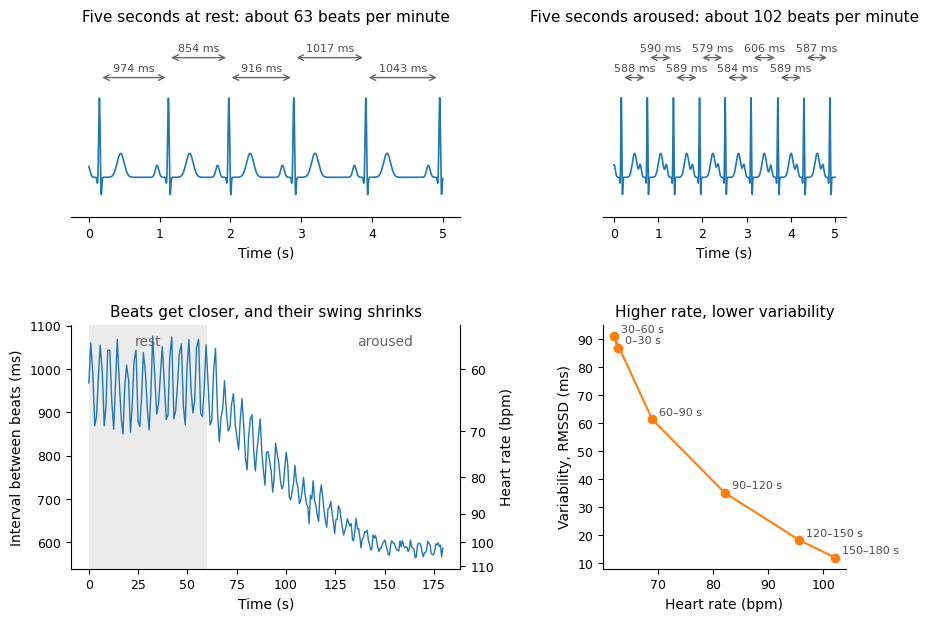

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.figsize": (10, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# A simulated three-minute recording of heartbeats. Heart rate climbs from rest to arousal, and the
# beat-to-beat variability shrinks as it does: the breathing-linked swing of the intervals gets smaller
# when the parasympathetic branch withdraws, and shorter intervals leave less room to vary in any case.
rng = np.random.default_rng(7)
t, rr, times = 0.0, [], []
while t < 180:
    phase = min(1.0, max(0.0, (t - 60) / 90))              # rest for a minute, then a 90 s rise, then a plateau
    hr = 62 + 40 * phase                                     # beats per minute
    mean_rr = 60 / hr                                        # seconds
    rsa = (0.09 - 0.07 * phase) * np.sin(2 * np.pi * t / 4.5)  # breathing-linked swing, 4.5 s per breath
    noise = (0.025 - 0.018 * phase) * rng.standard_normal()
    interval = max(0.3, mean_rr + rsa * mean_rr + noise)
    times.append(t); rr.append(interval); t += interval
times, rr = np.array(times), np.array(rr) * 1000             # ms

# heart rate and RMSSD in 30 s windows
edges = np.arange(0, 181, 30); hr_w, hrv_w = [], []
for a, b in zip(edges[:-1], edges[1:]):
    sel = (times >= a) & (times < b); ibi = rr[sel]
    hr_w.append(60000 / ibi.mean()); hrv_w.append(np.sqrt(np.mean(np.diff(ibi) ** 2)))

# the heartbeat signal itself, drawn as an idealised ECG on the simulated beat times
def ecg(beat_times, t0, t1, fs=500):
    tt = np.arange(t0, t1, 1 / fs); y = np.zeros_like(tt)
    for b in beat_times[(beat_times > t0 - 1) & (beat_times < t1 + 1)]:
        for centre, width, height in [(-0.16, 0.025, 0.15), (-0.025, 0.008, -0.10), (0.0, 0.010, 1.0), (0.025, 0.008, -0.25), (0.30, 0.050, 0.30)]:
            y += height * np.exp(-((tt - b - centre) ** 2) / (2 * width ** 2))
    return tt, y

fig = plt.figure(figsize=(10, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3], width_ratios=[1.6, 1], hspace=0.5, wspace=0.45)
for col, (t0, label) in enumerate([(20, "at rest"), (160, "aroused")]):
    ax = fig.add_subplot(gs[0, col]); tt, y = ecg(times, t0, t0 + 5)
    ax.plot(tt - t0, y, color="C0", lw=1.2); ax.set_ylim(-0.5, 1.85); ax.set_yticks([])
    ax.spines["left"].set_visible(False); ax.set_xlabel("Time (s)")
    beats = times[(times >= t0) & (times < t0 + 5)]
    for k, (a, b) in enumerate(zip(beats[:-1], beats[1:])):
        yy = 1.25 if k % 2 == 0 else 1.5                     # alternate heights so close labels do not collide
        ax.annotate("", (b - t0, yy), (a - t0, yy), arrowprops=dict(arrowstyle="<->", color="0.4", lw=1))
        ax.text((a + b) / 2 - t0, yy + 0.05, f"{(b - a) * 1000:.0f} ms", ha="center", va="bottom", fontsize=8, color="0.3")
    sel = (times >= t0) & (times < t0 + 30)
    ax.set_title(f"Five seconds {label}: about {60000 / rr[sel].mean():.0f} beats per minute")
ax0 = fig.add_subplot(gs[1, 0]); ax1 = fig.add_subplot(gs[1, 1])
ax0.plot(times, rr, color="C0", lw=1)
ax0.set_xlabel("Time (s)"); ax0.set_ylabel("Interval between beats (ms)")
ax0.set_title("Beats get closer, and their swing shrinks")
to_bpm = lambda x: 60000 / np.maximum(np.asarray(x, dtype=float), 1e-9)     # safe at zero, which matplotlib probes when placing ticks
sec = ax0.secondary_yaxis("right", functions=(to_bpm, to_bpm))                 # the same axis in beats per minute (the map is its own inverse)
sec.set_ylabel("Heart rate (bpm)")
ax0.axvspan(0, 60, color="0.92", lw=0); ax0.text(30, ax0.get_ylim()[1] * 0.98, "rest", ha="center", va="top", color="0.4")
ax0.text(150, ax0.get_ylim()[1] * 0.98, "aroused", ha="center", va="top", color="0.4")
ax1.plot(hr_w, hrv_w, "o-", color="C1")
for k, (x, y) in enumerate(zip(hr_w, hrv_w)):
    ax1.annotate(f"{int(edges[k])}–{int(edges[k+1])} s", (x, y), xytext=(5, 3), textcoords="offset points", fontsize=8, color="0.3")
ax1.set_xlabel("Heart rate (bpm)"); ax1.set_ylabel("Variability, RMSSD (ms)")
ax1.set_title("Higher rate, lower variability")
plt.show()


*Figure: A simulated three-minute recording in which heart rate climbs from rest to arousal. Top: five seconds of the heartbeat signal at rest and five seconds aroused, with the gap between successive beats marked; at a higher heart rate the beats come closer, so each interval is shorter. Bottom left: the interval between beats over the whole recording, shortening as the rate climbs, with the breathing-linked swing of the intervals shrinking too. Bottom right: heart rate against heart-rate variability (RMSSD) in 30-second windows of the same recording: as one rises, the other falls. Real recordings are noisier, but the direction is the same, which is why the two should never be read apart.*

A steady, slow pulse can slow a perceiver's breathing, and with it the heart, which speeds up slightly on each in-breath and slows on the out-breath ([respiratory sinus arrhythmia](https://en.wikipedia.org/wiki/Respiratory_sinus_arrhythmia)); faster music does the reverse. How much any one perceiver responds depends on baseline, training, familiarity, culture, mood, and attention, and on the setting: people listening together in a hall respond more, and more alike, than people listening alone.


### Interpersonal physiological responses

Advances in measurement now allow empirical study of [interpersonal](https://en.wikipedia.org/wiki/Interpersonal_relationship) physiological responses to music. As noted above, music can bring bodies into sync, both in performance and in perception. A common beat can make people breathe together, and once breathing is shared, heart rate, skin conductance and even brain activity can start to look more similar across perceivers or performers.

A few simple routes lead here. Sensorimotor entrainment ([sensorimotor synchronisation](https://en.wikipedia.org/wiki/Sensorimotor_synchronization)) means that moving, tapping or dancing together aligns bodily rhythms. [Emotional contagion](https://en.wikipedia.org/wiki/Emotional_contagion) describes how emotion spreads through a group and shifts autonomic signals like heart rate and skin conductance. [Social appraisal](https://en.wikipedia.org/wiki/Appraisal_theory) and hormonal responses&mdash;for example feeling connected or safe, sometimes linked to [oxytocin](https://en.wikipedia.org/wiki/Oxytocin)&mdash;can also increase physiological similarity.

:::{note} Dig deeper: measuring physiological coupling
:class: dropdown
We measure such interpersonal responses by looking for moment-to-moment similarity between signals such as heart rate and respiration. Common tools are [cross-correlation](https://en.wikipedia.org/wiki/Cross-correlation) (checking whether two signals rise and fall together, possibly with a delay), windowed [coherence](https://en.wikipedia.org/wiki/Coherence_(signal_processing)) or windowed correlation (testing similarity in short time windows to see when coupling appears), and [phase-locking](https://en.wikipedia.org/wiki/Phase_locking) (checking whether rhythmic signals keep a stable phase relationship). Because these signals run continuously, a good analysis says *when* people are coordinated, not only whether they are on average; {cite:t}`Upham2018` developed such an activity analysis for continuous responses to music.
:::

In a RITMO study of expert and student string quartets, the players' cardiac rhythms became more interrelated in passages of shared musical absorption {cite:p}`Hoffding2023`. In another study, MusicLab Copenhagen, the Danish String Quartet performed to both on-site and remove audiences. It was found that the audience in the hall felt more connected to each other than the streaming audience did {cite:p}`Swarbrick2023`. Interestingly, both felt equally connected to the performers, and the hall audience moved less during the classical pieces and more during the folk tunes. Coupling tends to be stronger when people interact directly, attend to the same thing, or are emotionally engaged with the music.

## Music and emotion

The signals described so far rarely appear on their own. A rising heart rate or a burst of sweat usually accompanies an emotional experience, so it is worth pausing to ask what an emotion actually is. In psychology, an [emotion](https://en.wikipedia.org/wiki/Emotion) is a relatively brief, intense reaction to something that matters to us, combining a subjective feeling, bodily changes, and often an urge to act. Hearing a sudden bang behind you, for example, joins the feeling of alarm to a racing heart and an impulse to duck. 

Emotions should not be confused with [moods](https://en.wikipedia.org/wiki/Mood_(psychology)), which last longer and are less clearly tied to a specific cause. An emotion is short, from seconds to minutes, while a mood lasts hours or days. An emotion is about something (a sudden chord or a face in the audience), while a mood has no clear object and colours whatever comes along. And an emotion is intense enough to change the body and prompt an action, while a mood is a lower, steadier background. Music works on both: a piece can induce an emotion at one moment but also shift a mood for the afternoon. 

The difference between emotion and mood matters for how they are measured. An emotion shows up in a physiological recording as a brief, phasic response time-locked to the moment that caused it; a mood shows up, if at all, as a slow change in the tonic level over the session, which is why it is so important to measure baseline values.

There is one more important thing to think of: the distinction between *perceived* versus *induced* emotion {cite:p}`Juslin2019`. Perceived emotion is what you recognise the music as expressing. Induced (or felt) emotion is what the music makes you feel. Most people would recognise a sad emotion in a ballad in minor. But it does not necessarily make you sad yourself. In fact, many people instead report feeling moved, comforted, or pleasantly melancholic. The two often overlap, but they can come apart, and every study of musical emotion has to state which of them it is measuring.

### Mapping emotions: the valence–arousal plane

Emotions can be described with categories (happy, sad, angry, tender) or with dimensions. The most widely used dimensional model in music research is the circumplex model of affect, also called the valence–arousal model, proposed by the American psychologist [James A. Russell](https://en.wikipedia.org/wiki/James_A._Russell) {cite:p}`Russell1980`. It arranges emotional states in a circle around two axes: [valence](https://en.wikipedia.org/wiki/Valence_%28psychology%29), running from unpleasant to pleasant, and arousal, running from calm to activated (see [emotion classification](https://en.wikipedia.org/wiki/Emotion_classification)). Happiness is pleasant and activated, sadness unpleasant and calm, anger unpleasant and activated, and relaxation pleasant and calm. The model is popular because two numbers are enough to place a track, or a single moment within it, on a map, as exemplified below.

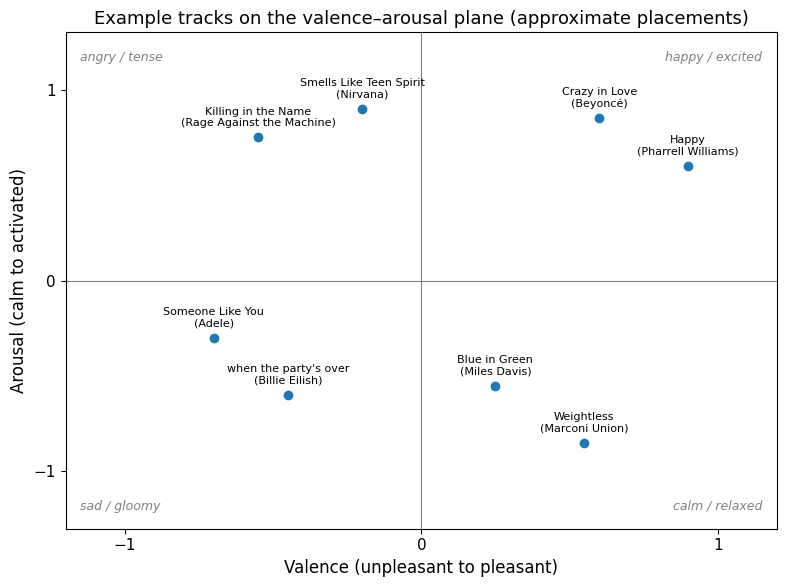

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.figsize": (10, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

tracks = {
    "Happy\n(Pharrell Williams)": (0.9, 0.6),
    "Crazy in Love\n(Beyoncé)": (0.6, 0.85),
    "Smells Like Teen Spirit\n(Nirvana)": (-0.2, 0.9),
    "Killing in the Name\n(Rage Against the Machine)": (-0.55, 0.75),
    "Someone Like You\n(Adele)": (-0.7, -0.3),
    "when the party's over\n(Billie Eilish)": (-0.45, -0.6),
    "Blue in Green\n(Miles Davis)": (0.25, -0.55),
    "Weightless\n(Marconi Union)": (0.55, -0.85),
}

fig, ax = plt.subplots(figsize=(10, 6))
for label, (v, a) in tracks.items():
    ax.plot(v, a, "o", color="tab:blue", markersize=6)
    ax.annotate(label, (v, a), textcoords="offset points", xytext=(0, 8),
                ha="center")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.text(-1.15, 1.15, "angry / tense", style="italic", color="grey", ha="left")
ax.text(1.15, 1.15, "happy / excited", style="italic", color="grey", ha="right")
ax.text(-1.15, -1.2, "sad / gloomy", style="italic", color="grey", ha="left")
ax.text(1.15, -1.2, "calm / relaxed", style="italic", color="grey", ha="right")
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.3, 1.3)
ax.set_xticks([-1, 0, 1])
ax.set_yticks([-1, 0, 1])
ax.set_xlabel("Valence (unpleasant to pleasant)")
ax.set_ylabel("Arousal (calm to activated)")
ax.set_title("Example tracks on the valence–arousal plane (approximate placements)")
plt.tight_layout()
plt.show()

*Figure: Examples of placements of some well-known tracks. Your own placements would differ; the map describes responses rather than properties of the audio file.*

### How music evokes emotions

The Swedish music psychologist Patrik Juslin has argued that musical emotions arise through a set of underlying psychological mechanisms, each of which also operates outside music {cite:p}`Juslin2019,JuslinSloboda2010`. The main ones are worth knowing:

- **Brain stem reflex**: Sudden, loud, or sharp events trigger the body's fast alarm circuits. A gunshot-like drum hit, or the drop in an EDM track, startles the body before any thinking has happened.
- **Rhythmic entrainment**: Bodily rhythms lock onto a strong external pulse. A steady four-on-the-floor EDM beat wind arousal on the dance floor.
- **Evaluative conditioning**: A piece heard repeatedly in happy settings eventually triggers the happiness by itself, a musical form of [classical conditioning](https://en.wikipedia.org/wiki/Classical_conditioning). The chime of an ice-cream van can still cheer up an adult decades later.
- **Emotional contagion**: We catch the emotion the music expresses, a voice cracking with grief in a ballad can pull the perceiver's own state along with it.
- **Visual imagery**: Music conjures [mental images](https://en.wikipedia.org/wiki/Mental_image), and the emotion follows the image. A slowly swelling synthesiser pad may evoke a sunrise, together with the calm that belongs to it.
- **Episodic memory**: Music tied to a specific [episodic memory](https://en.wikipedia.org/wiki/Episodic_memory) reawakens the feelings of that moment, which is why couples speak of "our song".
- **Musical expectancy**: Music sets up predictions and then confirms, delays, or violates them. Those prediction errors are felt as tension, surprise, and release {cite:p}`Huron2006`.

Remember that several of these mechanisms can run at once, and they also differ between people and situations. That is one reason the same song can give one person [chills](https://en.wikipedia.org/wiki/Frisson) and leave another cold. The list also explains why perceived and induced emotion may not be the same. You can recognise the grief in a ballad through contagion without feeling it yourself, or feel a surge of joy from an episodic memory attached to a song that expresses nothing joyful at all.

```{admonition} Question
:class: question
Can you think of a song that makes you feel something different from what it expresses? Which of the mechanisms above might explain the mismatch?
```

Sad music is the classic test case for these mechanisms. Jonna Vuoskoski and [Tuomas Eerola](https://en.wikipedia.org/wiki/Tuomas_Eerola) showed with indirect measures that sad music induces genuine sadness rather than only a recognition of it {cite:p}`Vuoskoski2012Sad`, and that the people who enjoy sad music tend to score high on empathy and openness to experience {cite:p}`Vuoskoski2012Who`. Later they found that the pleasure that sad music gives is carried not by the sadness but by the feeling of being moved, which rises with the sadness and is what listeners come back for {cite:p}`Vuoskoski2017`. Empathy also predicts how strongly a perceiver catches the emotion that music expresses, which is one reason the contagion mechanism varies so much from person to person.

### Measuring musical emotions

It is impossible to measure an emotion. The most direct tool is self-report: asking perceivers to rate valence and arousal, pick emotion words, or move a slider while the music plays. Such self-reports reach the felt experience, but it depends on memory and vocabulary, and continuous rating is itself a task that changes the listening. 

Physiological signals cannot measure emotion directly, but they can reveal some of what happens in the middle. The benefit of such measurements is that they run continuously, do not interrupt the music, and cannot be embellished afterwards. However, a racing heart can mean joy, fear, or a flight of stairs. It is therefore common to combine self-reporting with physiological measurements.

:::{note} Dig deeper: which emotion model to use
:class: dropdown
Which emotion words or dimensions to offer is itself a research question. A comparison of the discrete model (happy, sad, tender, fearful, angry) with the dimensional one (valence, arousal) on the same film music excerpts found both workable, with the dimensional model coping better with ambiguous examples {cite:p}`Eerola2011`. Continuous ratings add the time dimension. When several hundred perceivers rated moment by moment how moved they felt, the experience showed the same pattern of appraisals and bodily sensations as being moved by social scenes in film, which supports the view of feeling moved as a social emotion {cite:p}`Vuoskoski2022`.
:::

### Experiencing chills

Some passages of music give people goosebumps, a shiver, or a cold feeling down the spine. These *chills* (also called frisson) are brief peaks of emotion, and they leave a clear trace in the body: the skin conducts more, heart rate and breathing change for a few seconds, the hairs on the arms stand up, and the pupils widen. The pupil response is large enough to serve as a marker. In a study at the University of Oslo, perceivers' pupils dilated at the moments in the music where they reported chills, and most strongly for music they had chosen themselves {cite:p}`Laeng2016`; [the brain](the-brain.ipynb) chapter picks up what happens in the reward system at the same moments. The usual triggers are an unexpected harmonic turn, a crescendo reaching its peak, a voice entering close to the microphone, or a passage tied to a personal memory, which is to say the mechanisms above at work: expectancy, contagion, and episodic memory. Who gets chills, and from what, varies widely with personality, familiarity, and attention, and there is no single most chill-inducing piece: music people choose themselves works far better than anything an experimenter picks. What transfers between people is the kind of moment. When [John Sloboda](https://en.wikipedia.org/wiki/John_Sloboda) asked listeners which passages gave them shivers, the same structural events were named again and again: a new or unprepared harmony, a sudden change of dynamics or texture, a melodic appoggiatura, a cadence long delayed {cite:p}`Sloboda1991`.

```{admonition} Question
:class: question
Do you experience chills when listening to music? Are there any particular songs or musical features that more easily evoke chills?
```

:::{note} Dig deeper: ASMR, a neighbouring tingle
:class: dropdown
[Autonomous sensory meridian response](https://en.wikipedia.org/wiki/Autonomous_sensory_meridian_response) (ASMR) is another phenomenon that has drawn attention in recent years. If you haven't seen it, try to search for it on YouTube, and you will get lots of examples. It refers to a set of pleasurable, often tingling sensations and deep relaxation brought on by soft, intimate auditory and multimodal cues: whispering, close-mic breathing, gentle tapping, slow movements and binaural spatialisation. 

In sound and music research, ASMR is relevant because it shows how micro-acoustic features (low-level dynamics, spectral detail, and spatial cues) and a sense of interpersonal closeness modulate autonomic state. Many perceivers report calming, parasympathetic effects (slower breathing, lowered heart rate) alongside transient markers such as piloerection and occasional phasic skin-conductance rises.

ASMR and frisson can co-occur, but they differ phenomenologically and physiologically. ASMR is typically soothing and prolonged, whereas frisson is brief and strongly reward-linked. Analyses should therefore treat them as distinct response classes and include timing, valence and arousal measures to tell their profiles apart.
:::

## Measuring physiological reactions

Many physiological signals can be recorded. Here we look at some of the more common ones used in music research.

### Heart activity

There are two main ways to measure heart activity. The classic approach records the electrical signal using [electrocardiography](https://en.wikipedia.org/wiki/Electrocardiography) (ECG). Electrodes placed on the chest pick up the electrical signal of each heartbeat, which can be described as a PQRST signal, where the distance between the R peaks (the R–R interval) gives the heart rate.


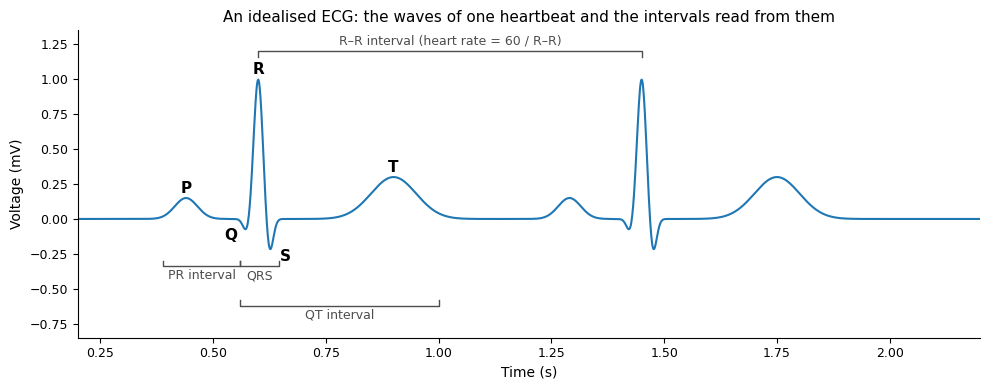

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.figsize": (10, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# An idealised ECG: each wave is a Gaussian bump with a typical timing (s), width (s), and height (mV)
# relative to the R peak. Two beats 0.85 s apart give a heart rate of about 70 bpm.
waves = {"P": (-0.16, 0.025, 0.15), "Q": (-0.025, 0.008, -0.10), "R": (0.0, 0.010, 1.0),
         "S": (0.025, 0.008, -0.25), "T": (0.30, 0.050, 0.30)}
fs, r_times = 1000, [0.6, 1.45]
t = np.arange(0, 2.2, 1 / fs)
ecg = np.zeros_like(t)
for r in r_times:
    for centre, width, height in waves.values():
        ecg += height * np.exp(-((t - r - centre) ** 2) / (2 * width ** 2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, ecg, color="C0", lw=1.5)
ax.set_xlabel("Time (s)"); ax.set_ylabel("Voltage (mV)")
ax.set_xlim(0.2, 2.2); ax.set_ylim(-0.85, 1.35)
r = r_times[0]
offsets = {"P": (0, 0.07), "Q": (-0.035, -0.02), "R": (0, 0.07), "S": (0.035, -0.02), "T": (0, 0.07)}   # label positions
for name, (centre, width, height) in waves.items():                 # label each wave of the first beat
    dx, dy = offsets[name]
    ax.annotate(name, (r + centre + dx, height + dy), ha="center", va="center", fontsize=11, fontweight="bold")

def bracket(x0, x1, y, label, below=True):
    """A horizontal bracket between x0 and x1 at height y, with a label."""
    tick = 0.04
    ax.plot([x0, x0, x1, x1], [y + tick, y, y, y + tick] if below else [y - tick, y, y, y - tick], color="0.3", lw=1)
    ax.text((x0 + x1) / 2, y - 0.02 if below else y + 0.03, label, ha="center", va="top" if below else "bottom", fontsize=9, color="0.3")

p_on, q_on, s_off, t_off = r - 0.21, r - 0.04, r + 0.045, r + 0.40
bracket(p_on, q_on, -0.34, "PR interval")
bracket(q_on, s_off, -0.34, "QRS")
bracket(q_on, t_off, -0.62, "QT interval")
bracket(r_times[0], r_times[1], 1.2, "R–R interval (heart rate = 60 / R–R)", below=False)
ax.set_title("An idealised ECG: the waves of one heartbeat and the intervals read from them")
plt.tight_layout()
plt.show()


*Figure: An idealised ECG trace of two heartbeats. The P wave is the atria contracting, the QRS complex the ventricles contracting, and the T wave the ventricles recovering. The PR interval, the QRS width, and the QT interval are what a clinician reads; the R–R interval between beats is what music research mostly uses, since it gives the heart rate and its variability.*

Many people now wear watches with built-in [photoplethysmography](https://en.wikipedia.org/wiki/Photoplethysmography) (PPG), which measures heart rate using optical sensors. These are flexible, since they can measure at the wrist, finger or ear. However, they are more sensitive to motion than ECG and less reliable for short-term HRV or spectral analyses. As a rule of thumb, use ECG when you need a clean, high-quality signal, and PPG when simple heart-rate tracking is enough.

You can try PPG with nothing but a phone. The [Camera pulse](https://fourms.github.io/sensingsoundandmusic/apps/camera-pulse/) app reads the pulse from a fingertip pressed over the camera lens, or, more weakly, from the changing colour of the face in a webcam image, and shows the pulse wave, the heart rate, and a rough estimate of its variability.

```{admonition} Fun fact
:class: note
The heart pumps around 7,500 litres per day for an average adult at rest.
```

Heart rate (HR) is reported in beats per minute (bpm). Typical resting adult HR is around 60–100 bpm (well-trained athletes commonly 40–60 bpm; infants and children are considerably higher). When using heart rate in music research, it is important to record a baseline heart rate and use within-participant normalisation to account for differences in resting HR and fitness.

Heart-rate variability (HRV) adds complementary information about autonomic balance. Because it varies so much with heart rate, always analyse it alongside respiration and/or motion data, so you can tell autonomic effects apart from metabolic or motor ones.

### Respiration

[Respiration](https://en.wikipedia.org/wiki/Respiration_(physiology)) is the record of how people breathe. The main variables to look at are breathing rate (breaths per minute), tidal depth (how big each breath is), the timing of inhalation versus exhalation, and instantaneous breathing phase (where in the breath cycle you are at any moment). Typical resting adult values: breathing rate ≈ 12–20 breaths/min, tidal volume ≈ 400–600 mL per breath, and an inspiratory:expiratory ratio around 1:2 (inspiration ≈ 1.5–2.0 s, expiration ≈ 2.5–3.5 s at ~12 bpm).

A common respiration device is the [spirometer](https://en.wikipedia.org/wiki/Spirometer), which gives precise measurements of air flow and volume. It requires a mouthpiece, though, so it is not very practical for musical purposes. A [respiratory inductance plethysmography](https://en.wikipedia.org/wiki/Plethysmograph) (RIP) belt is more practical, as it fits around the chest. It captures respiration phase and timing well, but is less accurate for absolute lung volume.

```{image} figures/physiology/01-product-points-eqlifemonitor.jpg
:alt: Equivital
:width: 100%
```

*We have a large number of EQ02 LifeMonitor sensor vests from Equivital that measure respiration, heart rate, and accelerometry in one device.*

Breathing can also be read from motion. A phone lying flat on the chest or belly records the rise and fall of each breath with its built-in accelerometer, and a webcam sees the same movement of the shoulders and chest. The [Breathing monitor](https://fourms.github.io/sensingsoundandmusic/apps/breathing-monitor/) app uses either source to draw the breathing waveform, mark each breath, and estimate the rate, which is close to what a belt measures and far from what a spirometer measures: the movement of the chest, not the air that moves.

```{exercise} Breathe, speak, sing
Open the [Breathing monitor](https://fourms.github.io/sensingsoundandmusic/apps/breathing-monitor/) and record one minute of each: sitting at rest, reading this paragraph aloud, and singing or humming one long note at a time. Compare the three breathing rates and the shape of the waveform in each, and note where the exhalations got longer. Then switch on the pacing tone at six breaths per minute and breathe with it for a minute: how far did the rate fall, and how regular did the intervals become?
```

### Body temperature

Body temperature has not traditionally been studied much in music research. Some research groups can now capture it with sensor vests, though, so it is becoming possible to study it. Medical applications often measure temperature rectally or tympanically, but for musical purposes skin temperature is more relevant, and there the relative change matters more than the absolute value. Skin temperature also changes slowly, over seconds to minutes, so expect gradual trends rather than sharp, moment-to-moment peaks in response to musical events.

We have also started capturing body temperature with [thermal cameras](https://en.wikipedia.org/wiki/Thermography#Cameras). One benefit is that a single camera can cover a large group, such as a whole orchestra or audience. Since these cameras only record temperature, they also effectively anonymise the data. Until recently their resolution was too poor to be useful, but the latest cameras offer higher resolution and frame rates, which makes them far more useful for analysis.

### Skin conductance

Skin conductance (also called [electrodermal activity](https://en.wikipedia.org/wiki/Electrodermal_activity), EDA) is a simple way to index sympathetic arousal. When people are surprised, excited, or stressed, sweat-gland activity changes and the skin conducts electricity differently. In recordings we separate a slow baseline level (skin conductance level, SCL) from quick event-linked peaks ([skin conductance responses](https://en.wikipedia.org/wiki/Skin_conductance_response), SCRs). In music studies you typically expect SCR peaks after surprising or high-arousal moments, and SCL shifts when arousal stays elevated.

EDA is best captured from stable sites such as the palms, where the signal is strongest. The participant should sit still, because motion makes the signal noisy. It also helps to record and report the likely confounds&mdash;room temperature and humidity, skin hydration, electrode placement, movement, and relevant medications&mdash;and to correct statistically for multiple trials or comparisons where needed.

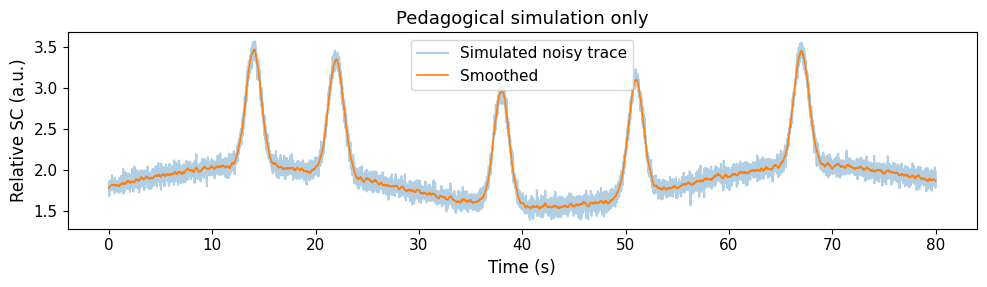

In [3]:
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.figsize": (10, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

rng = np.random.default_rng(42)
t = np.linspace(0, 80, 8000)
tonic = 1.8 + 0.25 * np.sin(2 * np.pi * t / 55.0)
phasic = np.zeros_like(t)
for centre in (14.0, 22.0, 38.0, 51.0, 67.0):
    phasic += 1.4 * np.exp(-((t - centre) ** 2) / 1.1)
noise = 0.06 * rng.standard_normal(len(t))
raw = tonic + phasic + noise
smooth = savgol_filter(raw, window_length=51, polyorder=3)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, raw, alpha=0.35, label="Simulated noisy trace")
ax.plot(t, smooth, lw=1.2, label="Smoothed")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Relative SC (a.u.)")
ax.set_title("Pedagogical simulation only")
ax.legend()
plt.tight_layout()
plt.show()


*Figure: A simulated trace of a skin-conductance signal: a slowly drifting level with short bursts on top.*

### Muscle tension

Every time a muscle contracts, its fibres fire small electrical pulses. [Electromyography](https://en.wikipedia.org/wiki/Electromyography) (EMG) picks up these pulses with electrodes on the skin over the muscle. The more fibres that fire, the stronger the signal, so EMG tells you when a muscle is active and roughly how hard it is working.

Music researchers use EMG for two kinds of questions. The first is about movement: when a performer's arm, finger or vocal muscles start to work, and how much effort a passage takes. The second is about reactions that are too small to see. The muscles of the face respond to music even when a perceiver sits still, a smile muscle can show whether a passage is felt as unpleasant or pleasant. In both cases, an EMG recording can supplement some of the other physiological signals: a rise in heart rate means one thing if the body was still and another if the person had just moved.

The raw EMG signal looks like noise, since it is the sum of many fibres firing at different times. Recordings are therefore typically smoothed to show its overall strength. In general, though, we find that EMG is a quite difficult signal to work with. The electrodes have to sit exactly over the muscle of interest, and any movement of the cable or the skin produces bumps that look like muscle activity. For that reason EMG should be compared to video or motion capture.

EMG can also be used to control sound. At UiO we have explored it for interactive music systems, as shown in the fourMs Lab video *MuMyo - exploring the Myo armband for musical interaction*:

<iframe width="560" height="315" src="https://www.youtube.com/embed/L98pL8CEftA?si=5UeApe7h5JdejUGZ" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" referrerpolicy="strict-origin-when-cross-origin" allowfullscreen></iframe>

## Interpreting the signals

The signals above differ in what they index, how fast they change, and how easily they are disturbed. This section compares them and lists the mistakes that are easiest to make.

### Comparison

The table below compares the signals discussed above: what each one captures, how it is measured, and how fast it varies.

:::{note} Dig deeper: sampling rates for body signals
:class: dropdown
Recall the sampling theorem from the [electroacoustics](electroacoustics.ipynb) chapter: the sampling rate must be at least twice the highest frequency in the signal. In practice, physiological recording often samples far above that minimum, since many analyses need precise event timing rather than just the waveform. Heartbeats arrive only about once per second, but locating each R peak to within a millisecond, which heart rate variability analysis requires, calls for ECG sampled at hundreds of hertz.
:::

| Signal | Indexes | Sensor | Content (Hz) | Sampling (Hz) |
|---|---|---|---|---|
| ECG | Heartbeat timing, HR, HRV | Chest electrodes | Beats at 1–3; waveform to ~150 | 250–1000 |
| PPG | Heart rate, pulse wave | Optical, wrist or finger | Beats at 1–3; pulse wave to ~15 | 50–200 |
| EDA | Sympathetic arousal | Electrodes on palm or sole | Below 1; responses over 1–5 s | 10–50 |
| Respiration | Breathing rate, depth, phase | Belt, nasal cannula | 0.15–0.5 at rest; ~1 in exertion | 25–100 |
| Skin temperature | Peripheral blood flow | Thermistor, infrared | Below 0.1; drifts over minutes | 1–10 |
| EMG | Muscle activation, tension | Surface electrodes | Most energy at 20–450 | ≥1000 |

Each signal has its own trade-off:

- ECG is the reference for precise beat timing and HRV, but needs electrodes on the chest.
- PPG is easy to wear, but moves with the hand and is too noisy for short-term HRV.
- EDA indexes sympathetic activity directly, but also follows temperature, humidity, contact quality and movement.
- Respiration is needed to separate breathing effects from HRV; belts are robust but can slip, nasal sensors are precise but intrusive.
- Skin temperature shows slow vasomotor change over minutes, not phasic responses, and follows room and clothing.
- EMG separates motor from autonomic effects with millisecond resolution, but needs careful placement, normalisation and artefact control.

At RITMO, most of our studies compare heart rate (from ECG), respiration (from RIP belts), temperature (from belts or thermal cameras), and muscle activation (from EMG). We also always record these together with accelerometry and audio/video documentation, so that we can correct for contextual factors.

None of the physiological signals are easy to work with. Each one takes a good deal of pre-processing and analysis before it yields meaningful results. The payoff is that we can learn a lot about how people experience sound and music, with signals that are at least easier to interpret than brain measurements.

### Pitfalls, ethics, and everyday sensors

Since equipment is now readily available, many people start capturing physiological signals. However, it is challenging to capture good signals and they are easy to misinterpret. Also remember that consumer wearables&mdash;watches, rings, earbuds with heart-rate sensing&mdash;make ecological measurement easy, but they usually cannot substitute for research-grade ECG, belt-based respiration, or lab EDA when you need precise timing, validated HRV, or a stable tonic estimate. Treat their output as a source of trends and prompts, not as automatic ground truth.

As researchers, it is important to always consider the ethical dimensions of what we are doing. It is important to use informed consent that states the purpose, storage, sharing and withdrawal terms of data capture.

```{exercise} A research dilemma
You run a listening study with 30 participants and record their ECG. Because the study is about music and not about health, the consent form says that the recordings are anonymous: each file is named by a number, and the list linking numbers to names is deleted at the end of the session. While cleaning the data you notice that one recording shows an irregular heartbeat of a kind that a cardiologist would want to look at. The participant is probably unaware of it.

1. Can you still find out who this person is? If the key list is gone, what would it take, and would that itself be a breach of what they agreed to?
2. Suppose you can identify them. Do you have a duty to warn, given that you are a music researcher and not a clinician, and that you might be wrong?
3. What would you write in the consent form of your next study so that this situation is covered before it arises?
```


## A critical look: singing together, breathing together

A Swedish choir study once made headlines: singing together makes the singers' hearts beat as one. The story is still retold as proof that music bonds people through the body. The study itself, by Björn Vickhoff and colleagues in Gothenburg {cite:p}`Vickhoff2013`, is worth a closer look.

Fifteen choir singers did three tasks while their heart rate and breathing were recorded: humming one note, singing a hymn, and chanting a slow mantra. During the hymn and the mantra, the singers' heart rates rose and fell together. The reason is simple. Singing sets the breathing: a long exhalation on each phrase, a quick inhalation between phrases. Breathing in speeds the heart up and breathing out slows it down (this is the respiratory sinus arrhythmia from earlier in the chapter). When everyone breathes to the same phrases, everyone's heart follows the same pattern. The effect was strongest for the mantra, with its slow and regular phrases, and weakest for the hummed note, where each singer breathed when they liked.

So what does the study show, and what does it not?

- **The claim:** singing in a group synchronises breathing, and through it the heart.
- **The evidence:** heart rate and respiration recorded from fifteen singers in three tasks.
- **The mechanism:** mechanical and well understood. No bonding is needed to explain it.
- **The limit:** hearts that move together are not the same as people who feel together. Whether the shared breathing causes the sense of connection choir singers describe is a separate question, and this design cannot answer it.

That gap, between what the body measurably does and what the person says they feel, is where the interesting research happens. It is also where the overclaiming happens.

Later work has moved the question to the concert hall. Finn Upham's analyses of audience video show that perceivers' bodies follow the music even when they sit still, and that a moment of musical silence stills the whole audience at once {cite:p}`Upham2024`. Whether that shared stillness is felt as connection is, again, another question.


```{admonition} Chapter summary
:class: tip
Music changes what the body does, in performers and perceivers alike, and most of those changes are run by the autonomic nervous system: the sympathetic branch prepares for action, the parasympathetic branch restores calm. Performers show the music in heart rate, breathing and muscle work; perceivers calm down or activate with tempo, loudness and timbre; and when people play, sing or listen together their bodies can start to move in step. Emotions give these signals a frame: the valence–arousal plane for placing them, perceived against induced emotion, Juslin's mechanisms for how music reaches the body, and chills as the one musical emotion with a clear bodily signature. Each signal (ECG and PPG, respiration, skin temperature, skin conductance, EMG) indexes something different, changes at its own speed, and needs its own sampling rate and care. A recording only means something against a baseline and together with context, consumer wearables give trends rather than ground truth, and even lightweight sensing raises consent questions. The choir study shows the central caution: bodies that move together are not the same as people who feel together.
```

```{admonition} Questions
:class: question
1. Heart rate and heart rate variability usually move in opposite directions. Why, and what does each one tell you about the autonomic nervous system during music listening?
2. Pick a passage that moves you. Where does it sit on the valence–arousal plane, which of Juslin's mechanisms best explains your reaction, and would a physiological recording show it?
3. ECG, respiration belt, skin conductance, skin temperature and EMG each answer different questions. For a study of chills, which two would you record, and why those?
4. Why do most physiological studies record a baseline and video or motion capture alongside the body signals? Give one misreading that each of them prevents.
5. In the choir study, why did the singers' heart rates rise and fall together, and why does that not show that singing bonds them emotionally?
```

:::{seealso} Further reading
- **Juslin & Sloboda (eds.), *Handbook of Music and Emotion: Theory, Research, Applications* (Oxford University Press)** — a comprehensive reference that includes physiological responses to music. https://doi.org/10.1093/acprof:oso/9780199230143.001.0001
- **Patrik N. Juslin, *Musical Emotions Explained* (Oxford University Press)** — an accessible account of how music moves us, body and mind. https://doi.org/10.1093/oso/9780198753421.001.0001
:::

:::{tip} Explore interactively
- [Breath and pulse](https://fourms.github.io/sensingsoundandmusic/apps/breath-pulse/) — a paced-breathing guide and pulse-counting timer for the exercises in this chapter.
- [Camera pulse](https://fourms.github.io/sensingsoundandmusic/apps/camera-pulse/) — heart rate by photoplethysmography from a fingertip over the phone camera or from the face in a webcam, with a rough HRV estimate.
- [Breathing monitor](https://fourms.github.io/sensingsoundandmusic/apps/breathing-monitor/) — the breathing waveform and rate from a phone lying on the chest or from a webcam, with an optional pacing tone.
- [PhysioNet LightWAVE](https://physionet.org/lightwave/) — browse real ECG and respiration recordings in the browser and see what raw physiological data actually looks like.
- [Sensor Logger](https://www.tszheichoi.com/sensorlogger) — the phone app from [the body](the-body.ipynb) also logs heart rate from a connected watch, if you have one.
:::